# Assignment 10 — Model Optimization Pipeline
**7CS353 — Machine Learning Lab | TY B.Tech CSE | Semester V | AY 2025-26**
Walchand College of Engineering, Sangli

**Topic:** Regularization · Feature Importance · Hyperparameter Tuning
**Dataset:** `loan_approval.csv` (500 applicants, 10 features, binary target `approved`, seed = 353)

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

SEED = 353
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 100

## B1. Load Data and Establish a Baseline

In [2]:
df = pd.read_csv('loan_approval.csv')
print('Shape:', df.shape)
df.head()

Shape: (500, 11)


,age,income,loan_amount,credit_score,emp_years,debt_ratio,num_accounts,missed_payments,residence_years,num_inquiries,approved
0,21.7,54299.0,141510.0,669.0,5.3,0.456,2.0,2.0,11.8,2.0,1
1,33.6,56160.0,69808.0,529.0,15.5,0.404,6.0,0.0,0.0,3.0,0
2,43.6,61342.0,128854.0,665.0,20.9,0.316,2.0,2.0,0.8,4.0,1
3,47.8,87425.0,160389.0,725.0,7.8,0.379,2.0,2.0,0.0,1.0,1
4,29.3,50836.0,167581.0,630.0,8.0,0.440,2.0,1.0,8.3,1.0,0


In [3]:
# Basic data checks: types, missing values, class balance
print(df.dtypes, '\n')
print('Missing values per column:\n', df.isna().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum(), '\n')
print('Class balance (approved):\n', df['approved'].value_counts(normalize=True).round(3))

age                float64
income             float64
loan_amount        float64
credit_score       float64
emp_years          float64
debt_ratio         float64
num_accounts       float64
missed_payments    float64
residence_years    float64
num_inquiries      float64
approved             int64
dtype: object 

Missing values per column:
 age                0
income             0
loan_amount        0
credit_score       0
emp_years          0
debt_ratio         0
num_accounts       0
missed_payments    0
residence_years    0
num_inquiries      0
approved           0
dtype: int64 

Duplicate rows: 0 

Class balance (approved):
 approved
1    0.522
0    0.478
Name: proportion, dtype: float64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,500.0,37.992600,9.836636,21.00,30.40000,38.3500,44.100,65.000
income,500.0,56235.058000,17720.128047,15000.00,44052.00000,56451.5000,68991.750,112988.000
loan_amount,500.0,182671.120000,56269.139800,41016.00,144732.75000,183770.0000,219059.000,365613.000
credit_score,500.0,659.574000,78.741889,413.00,607.00000,661.5000,720.000,850.000
emp_years,500.0,7.867800,4.540517,0.00,4.60000,7.8000,11.100,22.900
debt_ratio,500.0,0.353216,0.123635,0.05,0.26775,0.3495,0.436,0.742
num_accounts,500.0,3.928000,1.944834,1.00,2.00000,4.0000,5.000,11.000
missed_payments,500.0,1.016000,1.053548,0.00,0.00000,1.0000,2.000,7.000
residence_years,500.0,6.971800,4.690423,0.00,3.20000,6.9000,10.300,21.500
num_inquiries,500.0,1.940000,1.384280,0.00,1.00000,2.0000,3.000,7.000


**Preprocessing plan:** there are no missing values and all features are numeric, so no imputation or encoding is needed. We (1) split into train/test **before** scaling (stratified, `random_state=353`) and (2) standardise features with `StandardScaler` fitted on the **training set only** to avoid data leakage. Scaling is essential here because Lasso/Ridge penalties and coefficient-magnitude comparisons are only meaningful when features are on the same scale.

In [8]:
X = df.drop(columns='approved')
y = df['approved']
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

scaler = StandardScaler().fit(X_train)          # fit on train only
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=feature_names, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=feature_names, index=X_test.index)

print('Train:', X_train_scaled.shape, ' Test:', X_test_scaled.shape)
print('Train mean (should be ~0):', X_train_scaled.mean().abs().max())

Train: (400, 10)  Test: (100, 10)
Train mean (should be ~0): 5.151434834260726e-16


In [9]:
# Baseline: default Logistic Regression (C=1.0) on all 10 scaled features
baseline = LogisticRegression(C=1.0, max_iter=1000)
baseline.fit(X_train_scaled, y_train)

y_pred_base = baseline.predict(X_test_scaled)
y_prob_base = baseline.predict_proba(X_test_scaled)[:, 1]

base_acc = accuracy_score(y_test, y_pred_base)
base_f1  = f1_score(y_test, y_pred_base)
base_auc = roc_auc_score(y_test, y_prob_base)

print('BASELINE (C=1.0, all 10 features)')
print(f'Accuracy : {base_acc:.4f}')
print(f'F1-score : {base_f1:.4f}')
print(f'ROC-AUC  : {base_auc:.4f}')

BASELINE (C=1.0, all 10 features)
Accuracy : 0.9300
F1-score : 0.9307
ROC-AUC  : 0.9876


**Interpretation (B1)**

- **AUC = 0.5** means the model has no discriminative ability: it ranks a random approved applicant above a random rejected one only 50% of the time, i.e. it is no better than a coin flip.
- **AUC = 1.0** means perfect separation: every approved applicant receives a higher predicted probability than every rejected one.
- **Baseline AUC = 0.9876** (accuracy 0.930, F1 0.931). This is very close to 1.0, so even the untuned model separates approved and rejected applicants almost perfectly. The dataset is therefore strongly learnable and the remaining gains from regularization and tuning will be small in AUC terms; their main value is a simpler, more stable and more explainable model.

## B2. Regularization — Ridge, Lasso and ElasticNet
### B2.1 Fit three regularized models (C = 0.1)

In [10]:
ridge = LogisticRegression(penalty='l2', C=0.1, max_iter=1000)
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.1)
enet  = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=0.1,
                           max_iter=10000, random_state=SEED)

models = {'Ridge (L2)': ridge, 'Lasso (L1)': lasso, 'ElasticNet (l1_ratio=0.5)': enet}
rows = []
for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    auc = roc_auc_score(y_test, m.predict_proba(X_test_scaled)[:, 1])
    rows.append({'Model': name, 'Test AUC': round(auc, 4),
                 'Non-zero coefs': int((m.coef_[0] != 0).sum())})

reg_results = pd.DataFrame(rows)
reg_results.loc[len(reg_results)] = ['Baseline (C=1, L2)', round(base_auc, 4), 10]
reg_results

,Model,Test AUC,Non-zero coefs
0,Ridge (L2),0.9852,10
1,Lasso (L1),0.9820,4
2,ElasticNet (l1_ratio=0.5),0.9840,6
3,"Baseline (C=1, L2)",0.9876,10


### B2.2 Lasso regularization path

In [11]:
C_values = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10]

path_coefs = []
for C in C_values:
    m = LogisticRegression(penalty='l1', solver='liblinear', C=C)
    m.fit(X_train_scaled, y_train)
    path_coefs.append(m.coef_[0])

path_df = pd.DataFrame(path_coefs, columns=feature_names, index=C_values)
path_df.index.name = 'C'
path_df.round(3)

,age,income,loan_amount,credit_score,emp_years,debt_ratio,num_accounts,missed_payments,residence_years,num_inquiries
C,,,,,,,,,,
0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
0.005,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
0.010,0.000,0.000,0.000,0.597,0.000,0.000,0.000,0.000,0.000,0.000
0.050,0.000,0.000,0.000,2.575,0.000,0.000,0.000,0.000,0.000,0.000
0.100,0.000,0.155,0.000,3.539,0.228,-0.297,0.000,0.000,0.000,0.000
0.500,0.144,0.706,-0.230,6.420,0.721,-0.947,0.058,0.000,0.119,0.031
1.000,0.197,0.926,-0.311,7.672,0.878,-1.202,0.099,0.013,0.222,0.091
5.000,0.254,1.232,-0.426,9.446,1.095,-1.555,0.137,0.070,0.354,0.157
10.000,0.263,1.288,-0.447,9.767,1.134,-1.619,0.142,0.079,0.377,0.166


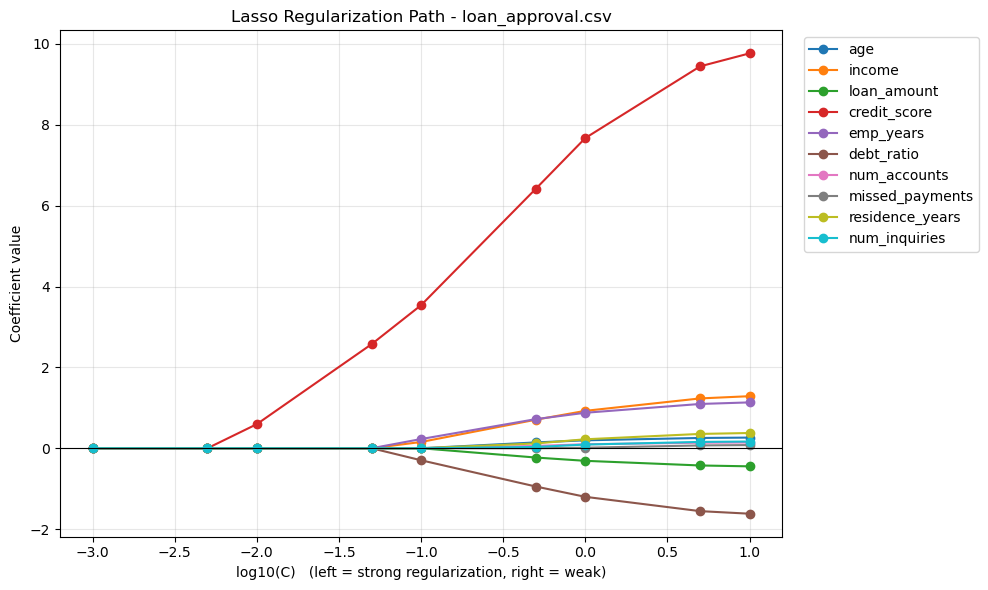

In [12]:
plt.figure(figsize=(10, 6))
for feat in feature_names:
    plt.plot(np.log10(C_values), path_df[feat], marker='o', label=feat)
plt.axhline(0, color='black', lw=0.8)
plt.xlabel('log10(C)   (left = strong regularization, right = weak)')
plt.ylabel('Coefficient value')
plt.title('Lasso Regularization Path - loan_approval.csv')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Order in which features become non-zero as C increases (i.e. the LAST to hit zero as C decreases)
entry_order = []
for C in C_values:
    for f in feature_names:
        if path_df.loc[C, f] != 0 and f not in [e[0] for e in entry_order]:
            entry_order.append((f, C))

print('Features in order of entering the model as regularization weakens:')
for i, (f, C) in enumerate(entry_order, 1):
    print(f'  {i:2d}. {f:16s} first non-zero at C = {C}')

never = [f for f in feature_names if f not in [e[0] for e in entry_order]]
print('\nNever non-zero on this grid:', never if never else 'none')

Features in order of entering the model as regularization weakens:
   1. credit_score     first non-zero at C = 0.01
   2. income           first non-zero at C = 0.1
   3. emp_years        first non-zero at C = 0.1
   4. debt_ratio       first non-zero at C = 0.1
   5. age              first non-zero at C = 0.5
   6. loan_amount      first non-zero at C = 0.5
   7. num_accounts     first non-zero at C = 0.5
   8. residence_years  first non-zero at C = 0.5
   9. num_inquiries    first non-zero at C = 0.5
  10. missed_payments  first non-zero at C = 1

Never non-zero on this grid: none


**Interpretation (B2.2):** reading the plot from right (weak regularization) to left (strong), every coefficient shrinks towards zero. All features except `credit_score` hit zero first as C decreases; `credit_score` is the last survivor and is the first feature to enter the model (non-zero from C = 0.01). It is followed by `income`, `emp_years`, `debt_ratio`. Features such as `num_accounts`, `residence_years`, `num_inquiries`, `missed_payments` only enter at large C (weak regularization) with tiny coefficients, so they are weakly predictive or redundant. At C = 0.001 and 0.005 the penalty is so strong that all coefficients are zero.

### B2.3 Ridge vs Lasso coefficients (C = 0.1)

In [14]:
coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Ridge coef (C=0.1)': ridge.coef_[0].round(4),
    'Lasso coef (C=0.1)': lasso.coef_[0].round(4),
})
display(coef_table)

n_zero_lasso = int((lasso.coef_[0] == 0).sum())
n_zero_ridge = int((ridge.coef_[0] == 0).sum())
print(f'\nLasso zeroes out {n_zero_lasso} of 10 features at C=0.1  (Ridge zeroes out {n_zero_ridge})')

,Feature,Ridge coef (C=0.1),Lasso coef (C=0.1)
0,age,0.1348,0.0000
1,income,0.2597,0.1551
2,loan_amount,-0.1118,0.0000
3,credit_score,2.4568,3.5388
4,emp_years,0.3485,0.2277
5,debt_ratio,-0.3285,-0.2973
6,num_accounts,0.0549,0.0000
7,missed_payments,0.0656,0.0000
8,residence_years,0.0122,0.0000
9,num_inquiries,-0.0240,0.0000



Lasso zeroes out 6 of 10 features at C=0.1  (Ridge zeroes out 0)


**Answer (B2.3):** Lasso sets **6 of the 10 features exactly to zero** at C = 0.1, keeping only `income`, `credit_score`, `emp_years`, `debt_ratio`. Ridge keeps all 10 features with non-zero (but shrunken) coefficients.

### B2.4 Why Ridge keeps all features but Lasso can zero some out
The L2 (Ridge) penalty region is a smooth circle/sphere, so the loss contours usually touch it at a point where *no* coordinate is exactly zero, and its gradient shrinks a weight in proportion to its size (it gets small but never exactly zero). The L1 (Lasso) penalty region is a diamond with sharp corners lying on the coordinate axes, and the loss contours very often first touch it at such a corner, which forces some weights to be exactly zero. Equivalently, the L1 penalty has a constant gradient (±λ) that can push a small weight all the way to zero, whereas the L2 gradient vanishes as the weight approaches zero, so Lasso performs built-in feature selection and Ridge only shrinks.

## B3. Feature Importance and Hyperparameter Tuning
Lasso coefficients are used as the feature-importance measure (features are standardised, so magnitudes are comparable).

### B3.1 Lasso (C = 0.1) feature importance

In [15]:
lasso_c01 = LogisticRegression(penalty='l1', solver='liblinear', C=0.1).fit(X_train_scaled, y_train)

importance = pd.DataFrame({
    'Feature': feature_names,
    'Coef': lasso_c01.coef_[0],
    'Abs coef': np.abs(lasso_c01.coef_[0]),
}).sort_values('Abs coef', ascending=False).reset_index(drop=True)
importance

,Feature,Coef,Abs coef
0,credit_score,3.538839,3.538839
1,debt_ratio,-0.297387,0.297387
2,emp_years,0.227684,0.227684
3,income,0.155118,0.155118
4,age,0.000000,0.000000
5,loan_amount,0.000000,0.000000
6,num_accounts,0.000000,0.000000
7,missed_payments,0.000000,0.000000
8,residence_years,0.000000,0.000000
9,num_inquiries,0.000000,0.000000


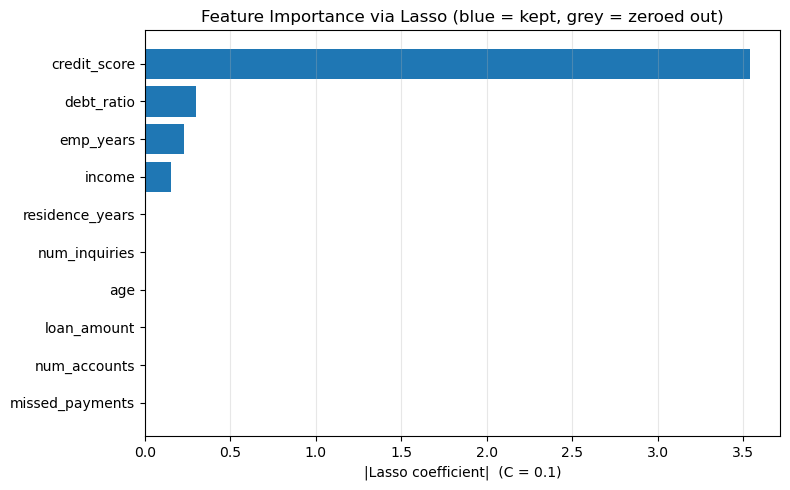

In [16]:
imp_plot = importance.sort_values('Abs coef', ascending=True)      # largest at top of barh
colors = ['tab:blue' if v > 0 else 'lightgrey' for v in imp_plot['Abs coef']]

plt.figure(figsize=(8, 5))
plt.barh(imp_plot['Feature'], imp_plot['Abs coef'], color=colors)
plt.xlabel('|Lasso coefficient|  (C = 0.1)')
plt.title('Feature Importance via Lasso (blue = kept, grey = zeroed out)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### B3.2 Drop zero-coefficient features and retrain the baseline

In [17]:
zero_feats = importance.loc[importance['Coef'] == 0, 'Feature'].tolist()
kept_feats = importance.loc[importance['Coef'] != 0, 'Feature'].tolist()
print('Zero-coefficient features (dropped):', zero_feats)
print('Kept features:', kept_feats)

X_reduced = X_train_scaled[kept_feats]
X_test_reduced = X_test_scaled[kept_feats]
print('\nX_reduced shape:', X_reduced.shape)

Zero-coefficient features (dropped): ['age', 'loan_amount', 'num_accounts', 'missed_payments', 'residence_years', 'num_inquiries']
Kept features: ['credit_score', 'debt_ratio', 'emp_years', 'income']

X_reduced shape: (400, 4)


In [18]:
reduced_model = LogisticRegression(C=1.0, max_iter=1000).fit(X_reduced, y_train)
reduced_auc = roc_auc_score(y_test, reduced_model.predict_proba(X_test_reduced)[:, 1])
reduced_acc = accuracy_score(y_test, reduced_model.predict(X_test_reduced))

print(f'Reduced-feature model (C=1, {len(kept_feats)} features)')
print(f'Test AUC : {reduced_auc:.4f}   (baseline {base_auc:.4f}, diff {reduced_auc-base_auc:+.4f})')
print(f'Accuracy : {reduced_acc:.4f}   (baseline {base_acc:.4f})')

Reduced-feature model (C=1, 4 features)
Test AUC : 0.9892   (baseline 0.9876, diff +0.0016)
Accuracy : 0.9500   (baseline 0.9300)


**Answer (B3.2):** dropping the 6 zero-coefficient features changes test AUC from 0.9876 to 0.9892 (difference +0.0016). Performance did **not** meaningfully suffer: the discarded features carried almost no extra signal (they were largely noise), so a model with only 4 features is essentially as good as the full one and is simpler and less prone to overfitting.

### B3.3 GridSearchCV on X_reduced

In [19]:
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid,
                    cv=5, scoring='roc_auc')
grid.fit(X_reduced, y_train)

print('best_params_ :', grid.best_params_)
print(f'best_score_  : {grid.best_score_:.4f}   (mean 5-fold CV AUC)')

best_params_ : {'C': 10}
best_score_  : 0.9866   (mean 5-fold CV AUC)


,C,Mean CV AUC,Std
0,0.001,0.9822,0.0108
1,0.010,0.9841,0.0105
2,0.100,0.9860,0.0084
3,1.000,0.9865,0.0088
4,10.000,0.9866,0.0089
5,100.000,0.9866,0.0089


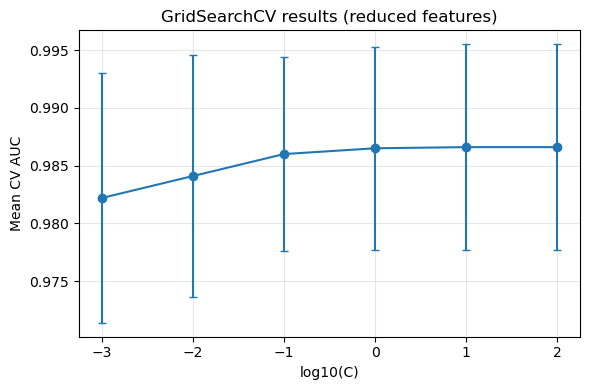

In [20]:
cv_table = pd.DataFrame({
    'C': param_grid['C'],
    'Mean CV AUC': grid.cv_results_['mean_test_score'].round(4),
    'Std': grid.cv_results_['std_test_score'].round(4),
})
display(cv_table)

plt.figure(figsize=(6, 4))
plt.errorbar(np.log10(cv_table['C']), cv_table['Mean CV AUC'], yerr=cv_table['Std'], marker='o', capsize=3)
plt.xlabel('log10(C)'); plt.ylabel('Mean CV AUC')
plt.title('GridSearchCV results (reduced features)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### B3.4 Evaluate the tuned model on the test set

In [21]:
best_model = grid.best_estimator_
tuned_auc = roc_auc_score(y_test, best_model.predict_proba(X_test_reduced)[:, 1])
tuned_acc = accuracy_score(y_test, best_model.predict(X_test_reduced))
tuned_f1  = f1_score(y_test, best_model.predict(X_test_reduced))
print(f'Tuned model: C={best_model.C}, Test AUC={tuned_auc:.4f}, Acc={tuned_acc:.4f}, F1={tuned_f1:.4f}')

summary = pd.DataFrame({
    'Model': ['Baseline (C=1, all features)', 'Lasso-reduced (C=1)', f'Tuned (best C={best_model.C}, reduced)'],
    'Features used': [10, len(kept_feats), len(kept_feats)],
    'Test AUC': [round(base_auc, 4), round(reduced_auc, 4), round(tuned_auc, 4)],
})
summary

Tuned model: C=10, Test AUC=0.9892, Acc=0.9500, F1=0.9515


,Model,Features used,Test AUC
0,"Baseline (C=1, all features)",10,0.9876
1,Lasso-reduced (C=1),4,0.9892
2,"Tuned (best C=10, reduced)",4,0.9892


**Interpretation (B3):** all three models reach essentially the same test AUC (0.9876 / 0.9892 / 0.9892), while the reduced models use only 4 instead of 10 features. Tuning selected C = 10. Because the test set has only 100 applicants, differences in the 3rd decimal are within noise; the practical conclusion is that regularization-based feature selection gives a much simpler model at no real cost in predictive power.

## B4. Design Task — Real-World Adaptation
> **Compliance requirement:** at most **5 features**, explainable to auditors in plain language, and **≥ 90 % of the baseline AUC**.

### B4.1 Select exactly 5 features
Evidence used: (i) the order in which features enter the Lasso path (B2.2) on a finer grid of C, and (ii) the |coefficient| ranking at C = 0.1 (B3.1), plus a check at a weaker penalty (C = 0.5) to rank features beyond the 4 that survive at C = 0.1.

In [22]:
# Fine-grained Lasso path to find when each feature first becomes non-zero
fine_C = np.logspace(-2, 1, 120)
entry_C = {}
for C in fine_C:
    m = LogisticRegression(penalty='l1', solver='liblinear', C=C).fit(X_train_scaled, y_train)
    for f, c in zip(feature_names, m.coef_[0]):
        if c != 0 and f not in entry_C:
            entry_C[f] = C

entry_df = (pd.Series(entry_C, name='C where feature enters').reindex(feature_names)
              .sort_values().to_frame())
entry_df['|coef| at C=0.1'] = pd.Series(np.abs(lasso_c01.coef_[0]), index=feature_names)
m05 = LogisticRegression(penalty='l1', solver='liblinear', C=0.5).fit(X_train_scaled, y_train)
entry_df['|coef| at C=0.5'] = pd.Series(np.abs(m05.coef_[0]), index=feature_names)
entry_df.round(4)

,C where feature enters,|coef| at C=0.1,|coef| at C=0.5
credit_score,0.0100,3.5388,6.4204
emp_years,0.0538,0.2277,0.7207
debt_ratio,0.0538,0.2974,0.9470
income,0.0641,0.1551,0.7063
loan_amount,0.1286,0.0000,0.2298
age,0.1531,0.0000,0.1442
num_accounts,0.2735,0.0000,0.0580
residence_years,0.2735,0.0000,0.1190
num_inquiries,0.3875,0.0000,0.0315
missed_payments,0.8241,0.0000,0.0000


In [23]:
top5 = entry_df.index[:5].tolist()
print('Selected 5 features:', top5)

X_train_5 = X_train_scaled[top5]
X_test_5  = X_test_scaled[top5]

Selected 5 features: ['credit_score', 'emp_years', 'debt_ratio', 'income', 'loan_amount']


**Justification (B4.1):** the five selected features are `credit_score`, `emp_years`, `debt_ratio`, `income`, `loan_amount`. They are the first five features to become non-zero along the Lasso path (B2.2), and the first four are exactly the survivors at C = 0.1 in the B3.1 ranking, with `credit_score` dominating by a large margin. The fifth feature, `loan_amount`, is the next one to enter the path and has the largest |coefficient| among the remaining features at the weaker penalty C = 0.5. Features that enter last or stay at zero (e.g. `residence_years`, `num_inquiries`, `missed_payments`) add very little signal.

### B4.2 Tune the regularization strength of the 5-feature model

In [24]:
grid5 = GridSearchCV(LogisticRegression(max_iter=1000), {'C': [0.001, 0.01, 0.1, 1, 10, 100]},
                     cv=5, scoring='roc_auc')
grid5.fit(X_train_5, y_train)

best5 = grid5.best_estimator_
auc5 = roc_auc_score(y_test, best5.predict_proba(X_test_5)[:, 1])
acc5 = accuracy_score(y_test, best5.predict(X_test_5))

print('best_params_ :', grid5.best_params_)
print(f'best CV AUC  : {grid5.best_score_:.4f}')
print(f'Test AUC     : {auc5:.4f}   Test accuracy: {acc5:.4f}')

best_params_ : {'C': 100}
best CV AUC  : 0.9880
Test AUC     : 0.9888   Test accuracy: 0.9500


### B4.3 AUC ratio vs. baseline

In [25]:
ratio = auc5 / base_auc * 100
print(f'5-feature AUC / baseline AUC = {auc5:.4f} / {base_auc:.4f} = {ratio:.2f} %')
print('Meets >= 90% constraint?  ', 'YES' if ratio >= 90 else 'NO')

5-feature AUC / baseline AUC = 0.9888 / 0.9876 = 100.12 %
Meets >= 90% constraint?   YES


In [26]:
# Auditor-friendly view: plain-language direction of each feature (standardised coefficients)
audit = pd.DataFrame({
    'Feature': top5,
    'Std. coefficient': best5.coef_[0].round(3),
    'Odds ratio per +1 SD': np.exp(best5.coef_[0]).round(3),
    'Effect on approval': np.where(best5.coef_[0] > 0, 'increases', 'decreases'),
}).sort_values('Std. coefficient', key=np.abs, ascending=False).reset_index(drop=True)
audit

,Feature,Std. coefficient,Odds ratio per +1 SD,Effect on approval
0,credit_score,9.398,12060.836,increases
1,debt_ratio,-1.510,0.221,decreases
2,income,1.217,3.376,increases
3,emp_years,1.143,3.135,increases
4,loan_amount,-0.540,0.582,decreases


**Answer (B4.3):** the 5-feature model has test AUC 0.9888 versus baseline 0.9876, a ratio of **100.12 %**, so it **meets** the ≥ 90 % constraint (it is also within a whisker of the full model).

### B4.4 Design report

**Design report**

**(a) Features selected and why.** I selected `credit_score`, `emp_years`, `debt_ratio`, `income`, `loan_amount`. These were the first five features to become non-zero along the Lasso regularization path and the first four are exactly the features with non-zero |coefficient| in the C = 0.1 Lasso model, so they carry the most predictive signal; `credit_score` is by far the most important (standardised coefficient ≈ 9.398). The remaining features were zeroed out or entered only with tiny coefficients, i.e. they are noise or redundant. All five are everyday credit concepts that an auditor can understand.

**(b) Regularization method and why.** I used **Lasso (L1)** for feature selection because it performs built-in selection by driving weak coefficients to exactly zero and gives a transparent ranking. For the final 5-feature model I used a standard L2-regularised logistic regression, with C tuned by 5-fold cross-validated GridSearch (best C = 100); L2 keeps the coefficients stable once the selection is done, and the model stays a plain logistic regression whose odds ratios can be explained in simple language.

**(c) If the 90 % constraint were not met.** I would first re-tune (a wider C grid, `class_weight`, and ElasticNet instead of pure Lasso, which is more stable when features are correlated). If that was not enough, I would engineer features (e.g. income-to-loan ratio, interaction terms), or swap the 5th feature for the next one in the ranking and compare by cross-validated AUC. As a last resort I would raise the issue with compliance, showing the AUC-vs-number-of-features trade-off, rather than silently using more than 5 features.

**(d) Fairness concern.** Even though protected attributes are not used, `age` and `income` are common proxies for them (age, gender, caste/religion or neighbourhood-linked income), and `credit_score` itself can encode historical inequality, so approval rates may differ across demographic groups. In a real bank I would audit approval rates and error rates (disparate impact, equal opportunity) by group, since a high overall AUC can hide poor performance for minority subgroups. Features such as `credit_score` and `income` favour applicants with existing credit history, which can unfairly exclude first-time borrowers.

**Result:** the 5-feature model achieves AUC 0.9888 = 100.12 % of the baseline, satisfying the compliance requirement.

## Conclusion
Regularization, Lasso-based feature selection and cross-validated tuning together reduce the model from 10 features to 4–5 without a meaningful loss in AUC. The result is a simpler, more explainable pipeline that satisfies the bank's compliance constraint.